In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sklearn as sk
%matplotlib inline

# Медицинская диагностика

In [2]:
data = np.loadtxt('https://raw.githubusercontent.com/kimve1969/mgu_ds_cours/refs/heads/main/semestr%202.2/files/hos13.dat', skiprows = 1)
print(data.shape)
print(data[:10, :])

(109, 3)
[[  1.1861009  83.14735     0.       ]
 [  1.3237845  67.08343     0.       ]
 [  0.8216278 120.00681     0.       ]
 [  1.1742367  56.82328     1.       ]
 [  1.1961126  84.18729     0.       ]
 [  1.479302   83.16051     0.       ]
 [  1.2122465  94.83045     0.       ]
 [  1.2161919  86.86843     0.       ]
 [  1.1841107  89.14896     0.       ]
 [  1.768121   62.16319     1.       ]]


In [4]:
X = data[:, :2]
y = np.array(data[:, 2], dtype = int)
N, d = X.shape
N, d

(109, 2)

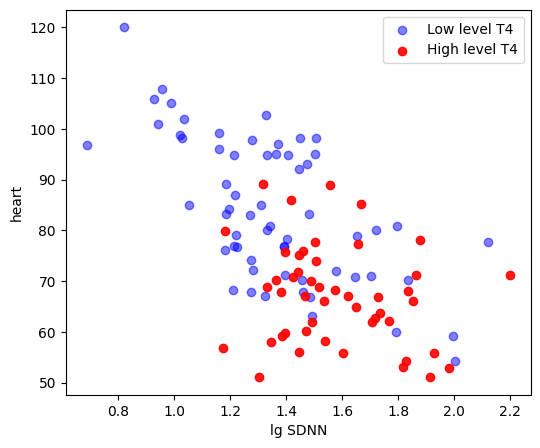

In [20]:
plt.figure(figsize = (6, 5))
plt.scatter(X[y == 0, 0], X[y == 0, 1], color = 'b', alpha = 0.9, label = 'Low level T4')
plt.scatter(X[y == 1, 0], X[y == 1, 1], color = 'r', alpha = 0.9, label = 'High level T4')
plt.xlabel('lg SDNN')
plt.ylabel('heart')
plt.legend()

In [29]:
from sklearn import neighbors
model = neighbors.KNeighborsClassifier(n_neighbors = 5)
model.fit(X, y)

KNeighborsClassifier()

In [22]:
print(model.predict([[30, 90]]))

[1]


In [23]:
print(model.predict_proba([[30, 90]]))

[[0.4 0.6]]


In [65]:
def draw_sep_curve(model, res = 100):
    xx0_min, xx0_max = plt.xlim()
    xx1_min, xx1_max = plt.ylim()
    xx0, xx1 = np.meshgrid(np.linspace(xx0_min, xx0_max, res), np.linspace(xx1_min, xx1_max, res))
    yy = model.predict(np.hstack((np.reshape(xx0, (res**2, 1)), np.reshape(xx1, (res**2, 1)))))
    yy = yy.reshape(xx0.shape)
    plt.contourf(xx0, xx1, yy, 1, alpha = 0.25, colors = ('b', 'r'))
    plt.contour(xx0, xx1, yy, 1, colors = 'k')
    plt.xlim((xx0_min, xx0_max))
    plt.ylim((xx1_min, xx1_max))


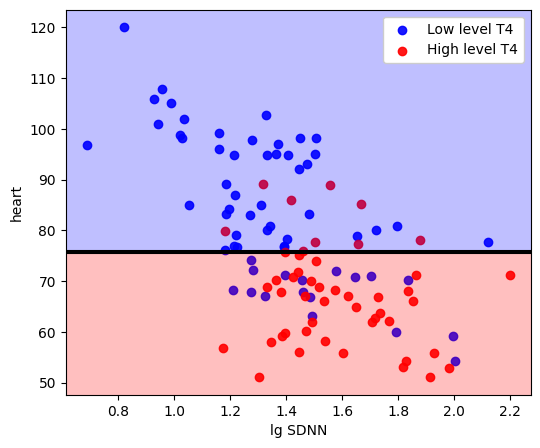

In [66]:
#import mysk
plt.figure(figsize = (6, 5))
#plt.scatter(X[y == 1, 0], X[y == 1, 1], color = 'b', alpha = 0.9, label = 'Low level T4')
#plt.scatter(X[y == 2, 0], X[y == 2, 1], color = 'r', alpha = 0.9, label = 'High level T4')
plt.scatter(X[y == 0, 0], X[y == 0, 1], color = 'b', alpha = 0.9, label = 'Low level T4')
plt.scatter(X[y == 1, 0], X[y == 1, 1], color = 'r', alpha = 0.9, label = 'High level T4')
#mysk.draw_sep_curve(model)
draw_sep_curve(model)
plt.xlabel('lg SDNN')
plt.ylabel('heart')
plt.legend(framealpha = 1)

Наверное, это не совсем то, что мы хотели...

In [68]:
x0_min, x0_max = X[:, 0].min(), X[:, 0].max()
x1_min, x1_max = X[:, 1].min(), X[:, 1].max()
d0 = x0_max - x0_min
d1 = x1_max - x1_min

In [69]:
from sklearn import preprocessing

#X_scaled = preprocessing.scale(X_train)

In [70]:
model = neighbors.KNeighborsClassifier(n_neighbors = 1, metric = 'minkowski',
                                       metric_params = {'w': [1./d0, 1./d1]})
model.fit(X, y)

KNeighborsClassifier(metric_params={'w': [np.float64(0.662756316034554),
                                          np.float64(0.014500663840390612)]},
                     n_neighbors=1)

In [71]:
print(model.predict([[2, 50]]))

[1]


In [72]:
print(model.predict_proba([[1, 170]]))

[[1. 0.]]


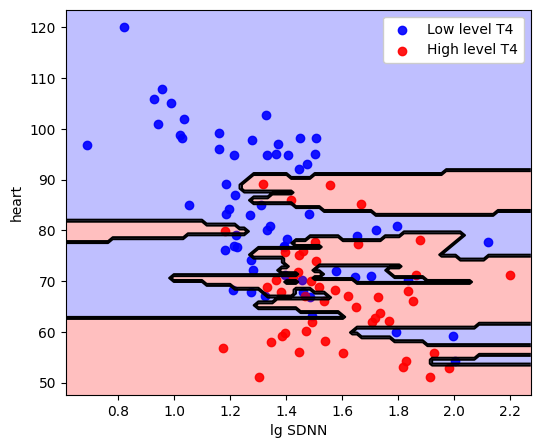

In [74]:
plt.figure(figsize = (6, 5))
#plt.scatter(X[y == 1, 0], X[y == 1, 1], color = 'b', alpha = 0.9, label = 'Low level T4')
#plt.scatter(X[y == 2, 0], X[y == 2, 1], color = 'r', alpha = 0.9, label = 'High level T4')
plt.scatter(X[y == 0, 0], X[y == 0, 1], color = 'b', alpha = 0.9, label = 'Low level T4')
plt.scatter(X[y == 1, 0], X[y == 1, 1], color = 'r', alpha = 0.9, label = 'High level T4')
#mysk.draw_sep_curve(model, res = 100)
draw_sep_curve(model, res = 100)
plt.xlabel('lg SDNN')
plt.ylabel('heart')
plt.legend(framealpha = 1)

### Перекрестный контроль

Как проверить качество модели?

Данных слишком мало, чтобы делить их на обучающую и тестовую выборки.

Будем использовать _перекрестный_ (или _скользящий_) _контроль_ (_cross-validation_)

In [75]:
#from sklearn import cross_validation
from sklearn import model_selection
model = neighbors.KNeighborsClassifier(n_neighbors = 1, metric = 'minkowski',
                                       metric_params = {'w': [1./d0, 1./d1]})
#scores = cross_validation.cross_val_score(model, X, y, cv = 10)
scores = model_selection.cross_val_score(model, X, y, cv = 10)
print(scores)
print("Accuracy: %0.2f (+/- %0.2f)" % (scores.mean(), scores.std() * 2))
print("Error:    %0.2f (+/- %0.2f)" % (1 - scores.mean(), scores.std() * 2))

[0.72727273 0.63636364 0.72727273 0.81818182 0.72727273 0.72727273
 0.72727273 0.72727273 0.45454545 0.4       ]
Accuracy: 0.67 (+/- 0.25)
Error:    0.33 (+/- 0.25)


In [76]:
N

109

In [77]:
#kk = [1, 3, 5, 7] + range(10, 85, 5)
kk = [1, 3, 5, 7] + list(range(10, 85, 5))
err_cv = []
for k in kk:
    model = neighbors.KNeighborsClassifier(n_neighbors = k)
    model.fit(X, y)
    #scores = cross_validation.cross_val_score(model, X, y, cv = 5)
    scores = model_selection.cross_val_score(model, X, y, cv = 5)
    err_cv.append(1 - scores.mean())

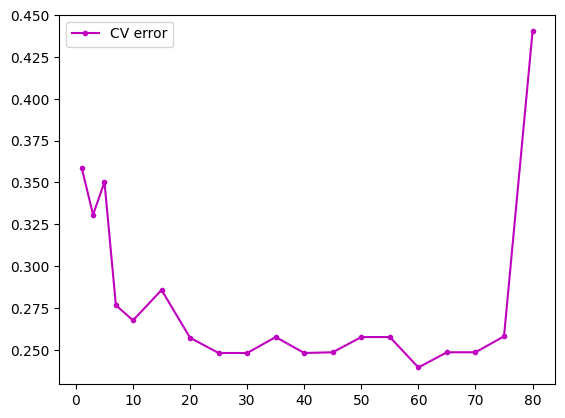

In [78]:
plt.plot(kk, err_cv, '.-m', label = 'CV error')
plt.legend(loc = 'best')

In [79]:
print(min(err_cv))
print(kk[err_cv.index(min(err_cv))])

0.23939393939393938
60


(85.0, 0.0)

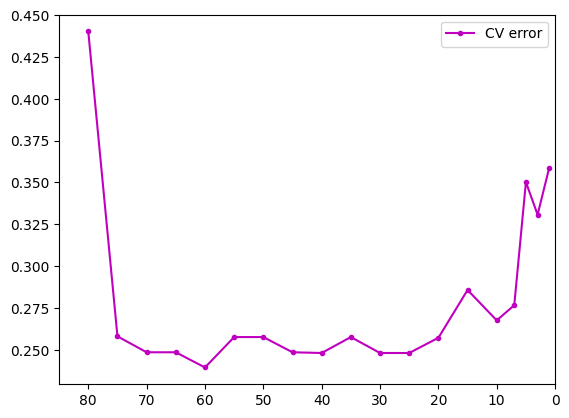

In [80]:
plt.plot(kk, err_cv, '.-m', label = 'CV error')
plt.legend(loc = 'best')
plt.xlim([85, 0])

## Стандартизация

In [81]:
from sklearn import preprocessing
X_scaled = preprocessing.scale(X)
print(X_scaled.mean(axis = 0))
print(X_scaled.std(axis = 0))

[-1.74681880e-16  1.57315547e-15]
[1. 1.]


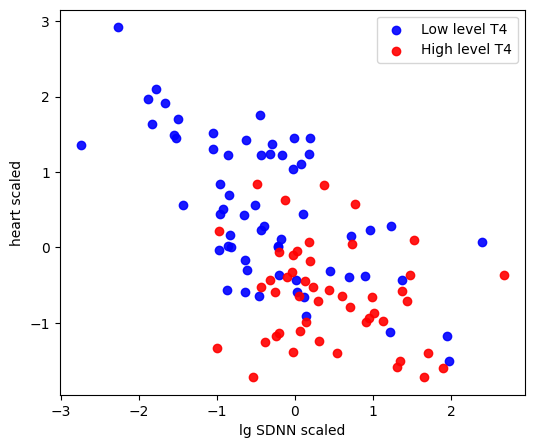

In [82]:
plt.figure(figsize = (6, 5))
#plt.scatter(X_scaled[y == 1, 0], X_scaled[y == 1, 1], color = 'b', alpha = 0.9, label = 'Low level T4')
#plt.scatter(X_scaled[y == 2, 0], X_scaled[y == 2, 1], color = 'r', alpha = 0.9, label = 'High level T4')
plt.scatter(X_scaled[y == 0, 0], X_scaled[y == 0, 1], color = 'b', alpha = 0.9, label = 'Low level T4')
plt.scatter(X_scaled[y == 1, 0], X_scaled[y == 1, 1], color = 'r', alpha = 0.9, label = 'High level T4')
plt.xlabel('lg SDNN scaled')
plt.ylabel('heart scaled')
plt.legend()

In [83]:
model_sc = neighbors.KNeighborsClassifier(n_neighbors = 1)
model_sc.fit(X_scaled, y)

KNeighborsClassifier(n_neighbors=1)

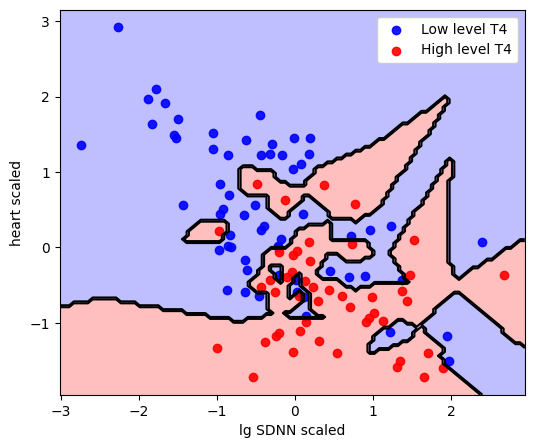

In [85]:
plt.figure(figsize = (6, 5))
#plt.contourf(xx, yy, zz, alpha = 0.25)
#plt.scatter(X_scaled[y == 1, 0], X_scaled[y == 1, 1], color = 'b', alpha = 0.9, label = 'Low level T4')
#plt.scatter(X_scaled[y == 2, 0], X_scaled[y == 2, 1], color = 'r', alpha = 0.9, label = 'High level T4')
plt.scatter(X_scaled[y == 0, 0], X_scaled[y == 0, 1], color = 'b', alpha = 0.9, label = 'Low level T4')
plt.scatter(X_scaled[y == 1, 0], X_scaled[y == 1, 1], color = 'r', alpha = 0.9, label = 'High level T4')
#sk_draw.draw_sep_curve(model_sc)
draw_sep_curve(model_sc)
plt.xlabel('lg SDNN scaled')
plt.ylabel('heart scaled')
plt.legend(framealpha = 1)

## Приведение к интервалу 0-1

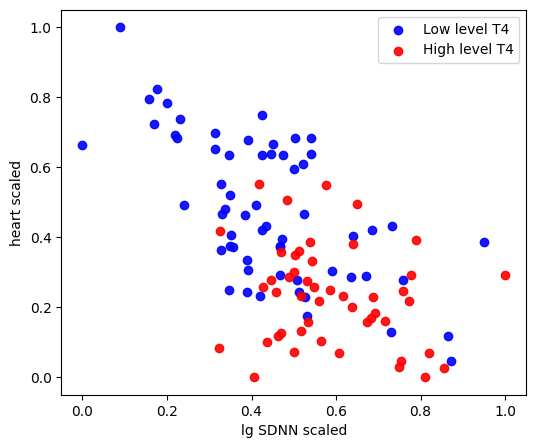

In [86]:
from sklearn import preprocessing
X_minmaxsc = preprocessing.MinMaxScaler().fit_transform(X)
plt.figure(figsize = (6, 5))
#plt.scatter(X_minmaxsc[y == 1, 0], X_minmaxsc[y == 1, 1], color = 'b', alpha = 0.9, label = 'Low level T4')
#plt.scatter(X_minmaxsc[y == 2, 0], X_minmaxsc[y == 2, 1], color = 'r', alpha = 0.9, label = 'High level T4')
plt.scatter(X_minmaxsc[y == 0, 0], X_minmaxsc[y == 0, 1], color = 'b', alpha = 0.9, label = 'Low level T4')
plt.scatter(X_minmaxsc[y == 1, 0], X_minmaxsc[y == 1, 1], color = 'r', alpha = 0.9, label = 'High level T4')
plt.xlabel('lg SDNN scaled')
plt.ylabel('heart scaled')
plt.legend()

Всегда ли полезна стандартизация/приведение к интервалу?